In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import AlgProxPen
from functions import quadratic

In [2]:
def test(dmin,dmax):
    res=np.zeros([6,dmax-dmin+1])
    k=0
    for d in np.arange(dmin,dmax+1):
        Y=[(0,1),(1,2.5)]
        n=int((d+1)*(d+2)/2)
        X=[]
        Y0=np.array([[0,1]])
        x0=np.zeros(n+1)
        def fcp(x):
            return x[-1]
        def df(x):
            v=np.zeros(n+1)
            v[-1]=1
            return v

        def f(x):
            return np.log(x[0]+x[1])*np.sin(x[0])
    
        def gcp(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return cp.abs(a-f(y))-x[-1]


        def g(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return np.abs(a-f(y))-x[-1]

        def poly(d,coeff,x):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=coeff[k]*x[0]**i*x[1]**(j-i)
                    k+=1
            return a
    
    
        res[1][k]=AlgProxPen(x0,Y0,fcp,gcp,g,X,Y,f=fcp,df=df,rho=1)[2]
        res[2][k]=AlgMePa(x0,Y0,fcp,gcp,g,X,Y,Ub=40*n)[2]
        res[3][k]=AlgBF(x0,Y0,fcp,gcp,g,X,Y)[2]
        res[4][k]=AlgRemez(x0,Y0,fcp,gcp,g,X,Y)[2]
        k+=1
    print("tempi medi/mediani Penalty",np.mean(res[1]),np.median(res[1]))
    print("tempi medi/mediani MePa",np.mean(res[2]),np.median(res[2]))
    print("tempi medi/mediani BF",np.mean(res[3]),np.median(res[3]))
    print("tempi medi/mediani Remez",np.mean(res[4]),np.median(res[4]))
    #plt.plot(m+10*np.arange(dmin,dmax+1),res[0])
    plt.plot(np.arange(dmin,dmax+1),res[1],"x")
    plt.plot(np.arange(dmin,dmax+1),res[2],"x")
    plt.plot(np.arange(dmin,dmax+1),res[3],"x")
    plt.plot(np.arange(dmin,dmax+1),res[4],"x")
    plt.legend(["Penalty", "MePa","BF","Remez"])
    plt.figure()
    labels=["Penalty", "MePa","BF","Remez"]
    d=[res[1],res[2],res[3],res[4]]
    plt.boxplot(d,showfliers=False,showmeans=True, meanline=True, tick_labels=labels)

In [3]:
test(3,10)

Time 0.7132365703582764
Time upper problem 0.3833043575286865
Time lower problem 0.32993221282958984
Feasibility 0.00045205837141820693
Final rho 2
Rho increases 1
Optimal value 0.052493234966810964
Value function call 10
Time 1.2495338916778564
Time upper problem 0.8321824073791504
Time lower problem 0.41735148429870605
Feasibility 0.0005839958786728978
Optimal value 0.0032950056618599394
Optimality cuts 2
Feasibility cuts 15
Value function calls 17
Time 1.2330856323242188
Time upper problem 0.8118820190429688
Time lower problem 0.42120361328125
Feasibility 0.0008458875450420124
Optimal value 0.0034404508949717914
Value function call 16
0.6666723166209502 1.7208251845703333
0.4877154909544249 0.9268143638805116
0.19713273262516304 0.3442637775243507
0.2214723694235997 0.1549071463850866
0.21133146358567353 0.06861047289661529
0.07182531243808453 0.04062948322988922
0.09468055806856962 0.02416061403845744
0.03927307155136835 0.008476737549336973
0.024083827676372217 0.00445256885100947

KeyboardInterrupt: 

In [15]:
def test1(d,iters):
    res=np.zeros([6,iters])
    for k in range(iters):
        Y=[(0,1),(1,2.5)]
        n=int((d+1)*(d+2)/2)
        X=[]
        y0=np.array([[0,1],[1,1]])
        x0=np.zeros(n+1)
        alpha=np.random.rand()*4+1
        beta=np.random.rand()*4+1
        gamma=np.random.rand()*4+1
        def fcp(x):
            return x[-1]

        def f(x):
            return np.log(alpha*x[0]+beta*x[1])*np.sin(gamma*x[0])
    
        def gcp(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return cp.abs(a-f(y))-x[-1]


        def g(x,y):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=x[k]*y[0]**i*y[1]**(j-i)
                    k+=1
            return np.abs(a-f(y))-x[-1]

        def poly(d,coeff,x):
            a=0
            k=0
            for i in range(d+1):
                for j in np.arange(i,d+1):
                    a+=coeff[k]*x[0]**i*x[1]**(j-i)
                    k+=1
            return a
    
    
        #res[0][k]=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,rho=1)[2]
        res[1][k]=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False,rho=1)[2]
        res[2][k]=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)[2]
        #res[3][k]=AlgBF(x0,y0,fcp,gcp,g,X,Y)[2]
        res[4][k]=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=False)[2]
        #res[5][k]=AlgRemez(x0,y0,fcp,gcp,g,X,Y)[2]
        k+=1
    print("tempi medi/mediani Penalty",np.mean(res[1]),np.median(res[1]))
    print("tempi medi/mediani MePa",np.mean(res[2]),np.median(res[2]))
    print("tempi medi/mediani BF",np.mean(res[4]),np.median(res[4]))
    #plt.plot(np.arange(dmin,dmax+1),res[0])
    plt.plot(np.arange(1,k+1),res[1])
    plt.plot(np.arange(1,k+1),res[2])
    #plt.plot(np.arange(dmin,dmax+1),res[3])
    plt.plot(np.arange(1,k+1),res[4])
    #plt.plot(np.arange(dmin,dmax+1),res[5])
    #plt.legend(["Penalization","PenalizationDropCuts", "MePa", "BF","BFDropCuts"])
    plt.legend(["Penalty", "MePa","BF"])

In [17]:
test1(8,10)


KeyboardInterrupt



In [11]:
#X,Y must be a box
Y=[(0,1),(1,2.5)]
d=3
n=int((d+1)*(d+2)/2)
X=[(-10,10) for i in range(n)]
X=np.append(X,[(0,100)],axis=0)

def fcp(x):
    return x[-1]

def f(x):
    return np.log(x[0]+x[1])*np.sin(x[0])
    
def gcp(x,y):
    a=0
    k=0
    for i in range(d+1):
        for j in np.arange(i,d+1):
            a+=x[k]*y[0]**i*y[1]**(j-i)
            k+=1
    return cp.abs(a-f(y))-x[-1]


def g(x,y):
    a=0
    k=0
    for i in range(d+1):
        for j in np.arange(i,d+1):
            a+=x[k]*y[0]**i*y[1]**(j-i)
            k+=1
    return np.abs(a-f(y))-x[-1]

def poly(d,coeff,x):
    a=0
    k=0
    for i in range(d+1):
        for j in np.arange(i,d+1):
            a+=coeff[k]*x[0]**i*x[1]**(j-i)
            k+=1
    return a

In [12]:
y0=np.array([0,1])
x0=np.zeros(n+1)
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y)

SystemError: <built-in function direct> returned a result with an exception set

In [ ]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

In [ ]:
res2=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)

In [ ]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y)

In [ ]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

In [8]:
res4=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 24.791351079940796
Time upper problem 22.46619439125061
Time lower problem 2.3251566886901855
Feasibility 9.731900277136496e-07
Optimal value 0.01866200492527265
Value function call 66


In [5]:
coeff=res1[0][:-1]
print(poly(d,coeff,y0))
print(f(y0))

-5.111054745910305e-05
0.0


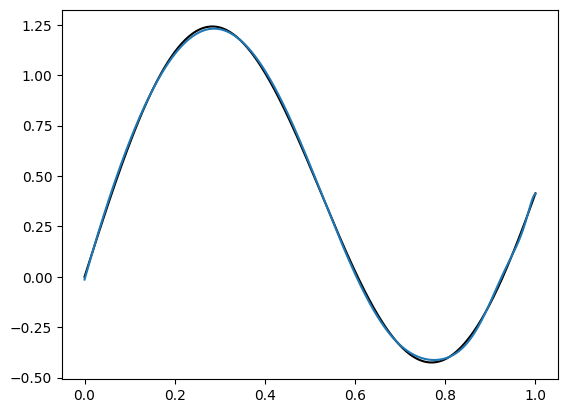

In [71]:
N = 400
x = np.linspace(Y[0][0], Y[0][1], N)


fig, ax = plt.subplots()
ax.plot(x, f(x), "k")
poly1=[poly(n,res1[0],xi) for xi in x]
ax.plot(x, poly1)

#ax.set(aspect=1)